[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/loem-ms/programming-for-information-systems-site/blob/main/content/downloads/Week_10.ipynb) · [Setup and saving](https://loem-ms.github.io/programming-for-information-systems-site/content/setup/)

**Before editing: File → Save a copy in Drive.** Support files are embedded; setup appears at their first use.


# Week 10 · Clean runs, command arguments and verification

<a id="start"></a>
[Session 1](#session-1) · [Session 2](#session-2) · [Session 3](#project-studio)


## Session 1 · Python foundations
<a id="session-1"></a>

Optional review before the final demonstration.


### Notebook state

Editing a cell does not run it. A clean check restarts the kernel and runs the documented cells in order, so hidden earlier state cannot supply an answer.

```python
count = 1
print(count)  # Changing the line above matters only after rerunning it.
```


### Fresh state and an alias

Two names can refer to the same dictionary. Calling a factory again creates an independent outer dictionary.

```python
first = {"count": 0}
alias = first
separate = {"count": 0}
first["count"] += 2
print(alias["count"], separate["count"])  # 2 0
```


### Reset and retry

A fresh run starts from the same initial state. A retry acts on the current state, which may already have changed.

```python
state = {"count": 0}
state["count"] += 2
state["count"] += 2
print(state["count"])  # 4 after a retry
```


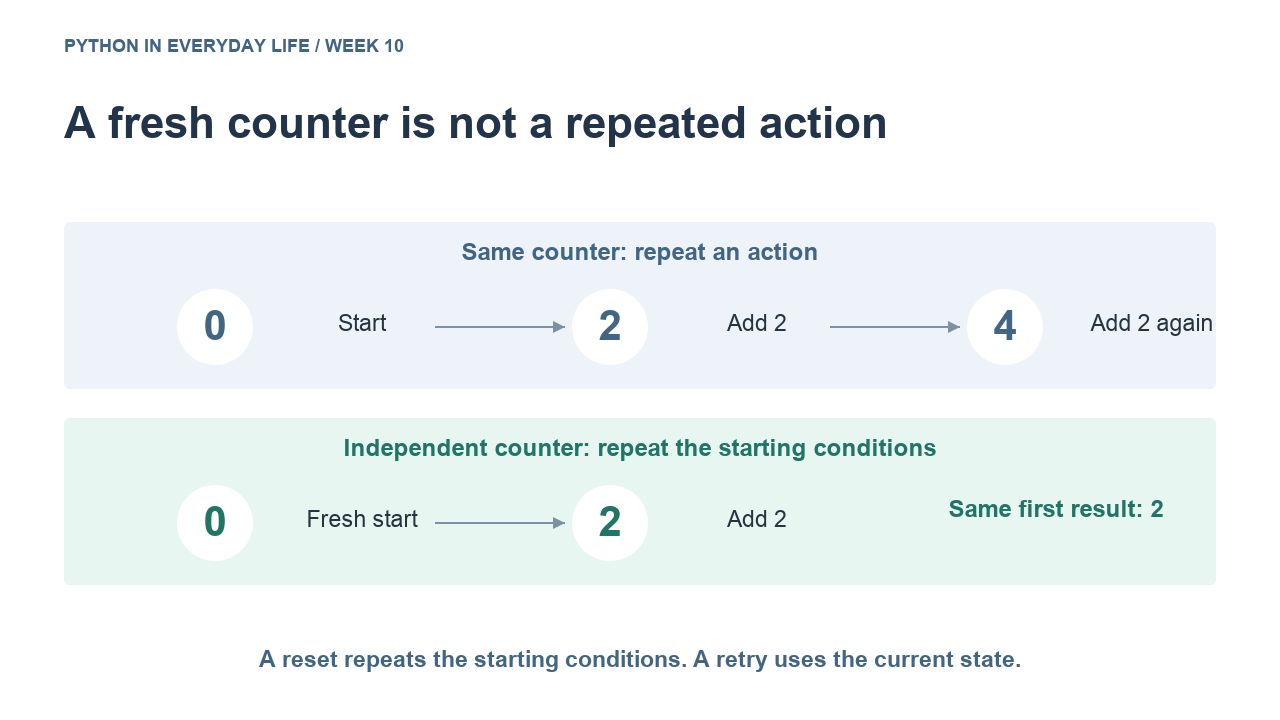


### Direct run and import

The main guard starts the workflow only on direct execution. Import makes definitions available without running the guarded call. main is an ordinary function name.

```python
def main(): print("Started directly")
if __name__ == "__main__": main()
```


### Command arguments

A command-line argument begins as text. Convert and validate it according to the program contract; the supplied CLI examples show the full command.

```python
argument = "3"
containers = int(argument)
```


### A reproducible check

State initial conditions and expected results. Reset external files or databases explicitly. A missing message or exception does not prove no state changed.

```python
def new_state(): return {"count": 0}
assert new_state() == {"count": 0}
```


### Example 1 · Optional review: fresh state versus another name

Use this only if shared state blocks your handoff. first and alias are two names for one dictionary; separate is another dictionary. Predict 1, 1, 0. The existing rehearsal then applies the same idea to a small operation. This is not extra assessed work.


In [ ]:
first = {"count": 0}
alias = first
separate = {"count": 0}
first["count"] += 1
print(first["count"], alias["count"], separate["count"])


In [ ]:
def new_counter():
    return {"count": 0}

def add_two(state):
    state["count"] += 2

first = new_counter()
second = new_counter()
add_two(first)
add_two(second)
print("Fresh runs:", first["count"], second["count"])
assert first == second == {"count": 2}
add_two(first)
print("Repeated action:", first["count"], "Independent counter:", second["count"])
assert first == {"count": 4}
assert second == {"count": 2}


The fresh runs print 2 2. Repeating add_two on first gives 4 while second stays 2. Each new_counter call creates a separate dictionary. Repeating an action on existing state differs from starting a fresh experiment.

In [ ]:
source = """def planned_portions(portions_per_container, containers):
    return portions_per_container * containers

def main():
    print("Planned portions:", planned_portions(3, 4))

if __name__ == "__main__":
    main()
"""
print("IMPORT context")
module = {"__name__":"practice_pickup"}
exec(source,module)
assert module["planned_portions"](3,3)==9
print("RUN context")
exec(source,{"__name__":"__main__"})

Import makes the function available without running the guarded main. Direct execution prints `Planned portions: 12`. The optional modified-guard exercise is included in Session 2 below.

The full CLI uses `argparse`: `--containers many` fails integer parsing, while `--containers 0` parses but violates the positive-container domain. The script reports failure on stderr and exits with status 2; success returns 0 through `SystemExit(main())`. Keep this practice-program evidence separate from tests of your actual project.

### Project files

Run this collapsed cell once, and again after a runtime restart. No ZIP, upload or network download is needed. Existing support files are preserved. Save created or edited files separately.


In [ ]:
# @title Prepare the course files (run after each runtime restart)
# Supplied programs, starter policy, CSV fixtures and diagrams are embedded here.
# This cell uses only Python's standard library. It makes no network request.
import base64 as _course_base64
import hashlib as _course_hashlib
import json as _course_json
import os as _course_os
from pathlib import Path as _CoursePath
import zlib as _course_zlib

_course_payload = '...'
_course_raw = _course_zlib.decompress(_course_base64.b64decode(_course_payload))
if _course_hashlib.sha256(_course_raw).hexdigest() != 'f14d1a0c0af069d5c453cb258a99ceefaecfd2a0764a02618d6e1fa16444cfb2':
    raise ValueError("Embedded course files are damaged; get a fresh notebook.")
_course_files = _course_json.loads(_course_raw)
_course_key = 'week_10_f14d1a0c0af0'
_course_roots = globals().setdefault("_course_workspace_roots", {})
if _course_key in _course_roots:
    _course_root = _CoursePath(_course_roots[_course_key])
elif all((_CoursePath.cwd() / _name).is_file() for _name in _course_files):
    # A complete extracted offline pack can be used in place.
    _course_root = _CoursePath.cwd()
else:
    _course_root = _CoursePath.cwd() / ".course_files" / _course_key
if _course_root.is_symlink() or any(_p.is_symlink() for _p in _course_root.parents):
    raise ValueError("Refusing a symbolic link in the course workspace")
_course_root.mkdir(parents=True, exist_ok=True)
for _name, _encoded in _course_files.items():
    _relative = _CoursePath(_name)
    if _relative.is_absolute() or ".." in _relative.parts:
        raise ValueError("Unsafe embedded support path")
    _target = _course_root / _relative
    if _target.is_symlink() or any(_p.is_symlink() for _p in _target.parents):
        raise ValueError("Refusing a symbolic link in the course workspace")
    _target.parent.mkdir(parents=True, exist_ok=True)
    if _target.exists() and not _target.is_file():
        raise ValueError("Course support path is not a regular file: " + str(_target))
    if not _target.exists():
        with _target.open("xb") as _output:
            _output.write(_course_base64.b64decode(_encoded))
_course_workspace_roots[_course_key] = str(_course_root.resolve())
_course_os.chdir(_course_root)
print("Course files ready:", _CoursePath.cwd())
print("Existing files were kept. Rerunning setup never replaces your edits.")
print("Save your notebook and download created/edited files before the runtime ends.")


### Revision: saved programs and their entry points

From `learning_materials/`, use the terminal commands below. These commands are not notebook Python statements.

**Choose the course interpreter.** In terminal examples, `python` means the Python used for your course environment. If setup created `.venv`, replace it with the operating-system-specific path in the [program guide](https://loem-ms.github.io/programming-for-information-systems-site/content/learning-materials/programs/readme/#choose-the-course-interpreter). That path changes when you change directories. In a notebook, `import sys; print(sys.executable)` shows the interpreter in use.

```text
python programs/first_pickup.py
python programs/pickup_app.py
python programs/rescue_cli.py --portions-per-container 3 --containers 4
python programs/rescue_cli.py --containers 3
python -m unittest discover -s programs -p "test_*.py"
```

Default planning inputs produce twelve portions; three containers produce nine. The practice files do not create reservations or record delivery. `main` is an ordinary function; the guard chooses when to call it. The following complete demonstration compares direct execution with import.

### 2. Reset and retry are different experiments

A reset recreates opening data for a comparison. A retry acts on possibly changed state. The next example shows both starting and resulting dictionaries. It deliberately omits duplicate identifiers to expose the effect of repeating an action.

In [ ]:
def reserve_two(state):
    if state["available"] < 2:
        raise ValueError("not enough containers")
    state["available"] -= 2
    state["reserved"] += 2

first={"available":5,"reserved":0}
second={"available":5,"reserved":0}
reserve_two(first); reserve_two(second)
assert first==second=={"available":3,"reserved":2}
reserve_two(first)
assert first=={"available":1,"reserved":4}
print("Repeated action:",first,"Independent fresh run:",second)
# No collection or delivery event is created by either reservation.

Both independent runs reserve two containers and leave three. Repeating on the first state reserves two more and leaves one. Neither result proves collection. In the full engine, request IDs and unique event keys reject repeats, but an error message alone is not an operator-friendly recovery policy.

The optional changed-input exercise is included in Session 2 below. The project handoff below applies this distinction to the real run instructions.

## Session 2 · Hands-on practice
<a id="session-2"></a>
<a id="practice-week-10"></a>

**Final-week exception:** the full operator demonstration remains required. The five leveled rehearsal choices below are optional. Choose only one that resolves an actual handoff problem during Session 1 preparation. Do not add extra practice during the assessment.

### P1 · Easy rehearsal: return a planning result

**Optional**

Optional Session 1 preparation only. Choose only if a missing return blocks your handoff. Write planning_total(unit, count), returning their product without printing inside. Call it with (3,4), store the result and print a labelled planning estimate. Predict 12. Add a zero-count check. Hint: return makes the value available to the caller; print only displays it. Stop after this resolves the actual issue.

In [ ]:
# Write your code here. Predict before running.


**Expected:** …  **Observed:** …  **Explanation:** …


### P2 · Easy rehearsal: validate command text

**Optional**

Optional Session 1 preparation only. Choose only if command text is causing a failure. Write parse_request_count(raw), converting text to an integer, rejecting counts <=0 with ValueError and returning the count otherwise. Predict "3" → 3, and ValueError for "0" and "many". Hint: conversion and range validation are separate steps; do not replace invalid text with a default. Write a caller that catches the two expected refusals.

In [ ]:
# Write your code here. Predict before running.


**Expected:** …  **Observed:** …  **Explanation:** …


### P3 · Optional rehearsal for a retry question

**Optional**

Optional only if your handoff has a reset/retry problem. During Session 1 rehearsal, write a tiny new_state() function returning a fresh dictionary with available 5 and reserved 0. Use the supplied reserve_two demo to compare two fresh runs with a repeated action. Write assertions for (3,2), (3,2), then (1,4). Explain why this teaching example does not establish the full engine’s duplicate-ID behavior. If your real guide already works, skip this task. Do not use protected Session 2 or 3 assessment time.

In [ ]:
# Optional: define new_state() and write the comparison assertions.
# Reuse reserve_two from the demonstration without changing it.


**Expected:** …  **Observed:** …  **Explanation:** …


### P4 · Application rehearsal: a guarded entry point

**Optional**

Optional Session 1 preparation only. Choose only if importing your program starts unwanted work. Write a separate practice module as the text in source: define planning_total, define main that prints "Planned portions: 12", then call main only under the __name__ guard. Use the supplied two execution contexts to check that import produces no output while direct execution prints one line. Keep this isolated from your real database. Hint: exec is supplied here only as a notebook-friendly way to compare module contexts; do not use it on untrusted text.

In [ ]:
import contextlib
import io
source = """
# Write your practice module here.
"""
import_output = io.StringIO()
run_output = io.StringIO()
with contextlib.redirect_stdout(import_output):
    exec(source, {"__name__": "practice_module"})
with contextlib.redirect_stdout(run_output):
    exec(source, {"__name__": "__main__"})
# Write assertions for the two outputs.


**Expected:** …  **Observed:** …  **Explanation:** …


### P5 · Challenge rehearsal: detect shared starting state

**Optional**

Optional Session 1 preparation only. Choose only if repeated tests affect each other. Write check_fresh_factory(factory): obtain two states, assert both start at available 5/reserved 0, apply the supplied reserve_two to the first, and assert the second stays unchanged. Test a correct factory that returns a new dictionary. Then test a deliberately wrong factory returning the same shared dictionary and prove your check catches it. Keep the wrong version isolated and never substitute it into the real engine. These flat-dictionary tests do not establish database reset behavior.

In [ ]:
# Reuse reserve_two from the Session 1 demo.
# Write check_fresh_factory(factory), a correct factory and a wrong copy.
# Assert that the correct version passes and the wrong version fails.


**Expected:** …  **Observed:** …  **Explanation:** …


These five choices are optional troubleshooting aids during Session 1 preparation. Choose only one that resolves an actual issue; they are not a five-task requirement. Keep Session 2 for the operator demonstration and Session 3 for independent verification. Do not add new project features.

### Project context

The fictional records distinguish planning, reservation, collection and delivery. Reproduce the supplied baseline from clean inputs, complete the requested written notes and explain a result independently. Improvements are optional.

### A new volunteer needs the evidence, not your memory

Your handoff should let another person reproduce the supplied system. They need known data, the run order, expected observations and a recovery step when results differ. No implemented improvement is required. If you made one, keep it separate from the unchanged baseline.

**Predict:** can repeating a reservation command be treated like opening a report again? Explain the possible state change before running the practice example.

![A handoff identifies starting data, run instructions, expected evidence and recovery.](https://loem-ms.github.io/programming-for-information-systems-site/learning_materials/assets/diagrams/w10_handoff.svg)

In [ ]:
# @title Show this lesson’s embedded diagram(s)
try:
    from IPython.display import SVG, display
except ImportError:
    print("Diagrams are in assets/diagrams; Jupyter or Colab displays them below.")
else:
    display(SVG(filename='assets/diagrams/w10_handoff.svg'))


### Handoff preparation

Review the project handoff checklist. Start with clean inputs, exchange run instructions and revise the first step the receiving volunteer cannot reproduce.

### Volunteer-led demonstration

<a id="operator-demo"></a>

Reproduce the supplied baseline from clean inputs and explain one input → processing → output trace. Let a peer follow your run guide and compare their observation with the expected result. Complete the requested notes and individual explanation. You may show an optional improvement afterward, clearly separated from the baseline.

**Demonstration sequence:** start clean, run the supplied system, compare results, let a peer reproduce it, and record a finding or an honest limitation.

### 3. Reproduce the canonical coordination day

Load the three CSVs and run the supplied engine. Keep a clean baseline for reproduction; optional changes use a separate copy. Explain why unreviewed P02 changes nothing and why P04's shortage on a later line must undo its earlier B01 decrement. Use explicit events to distinguish reserved, collected and delivered measures.

In [ ]:
from pathlib import Path
import csv

def fixture_directory():
    for candidate in (Path("final-data"), Path("learning_materials/final-data"), Path("../learning_materials/final-data")):
        if (candidate / "offer_batches.csv").is_file():
            return candidate.resolve()
    raise FileNotFoundError("Keep learning_materials/final-data with the teaching materials")

DATA_DIR = fixture_directory()

def read_fixture():
    with (DATA_DIR / "offer_batches.csv").open(encoding="utf-8", newline="") as file:
        batches = [(row["batch_id"], row["description"], int(row["portions_per_container"]),
                    int(row["opening_available"])) for row in csv.DictReader(file)]
    grouped = {}
    with (DATA_DIR / "pickup_requests.csv").open(encoding="utf-8", newline="") as file:
        for row in csv.DictReader(file):
            if row["reviewed"] not in ("yes", "no"):
                raise ValueError("reviewed must be yes or no")
            reviewed = row["reviewed"] == "yes"
            request = grouped.setdefault(row["request_id"], {"reviewed": reviewed, "lines": []})
            if request["reviewed"] != reviewed:
                raise ValueError("conflicting review flags within one request")
            request["lines"].append((row["batch_id"], int(row["containers"])))
    requests = [(request_id, item["reviewed"], item["lines"])
                for request_id, item in grouped.items()]
    with (DATA_DIR / "rescue_events.csv").open(encoding="utf-8", newline="") as file:
        events = [(row["request_id"], row["event_type"]) for row in csv.DictReader(file)]
    return batches, requests, events

batches, requests, events = read_fixture()
print("Fixture:", len(batches), "batches;", len(requests), "requests;", len(events), "events")

### Supplied setup: run once, then continue

**No editing required in the engine below.** Run the fixture-loading cell above, then run this supplied engine cell to create the known starting database. Rerunning it resets the fixture; it does not retry an operation against the previous state.

The implementation may be collapsed by your notebook viewer. You may inspect it later, but your task is the behavior requested next. After setup, [continue to your project task](#project-task).

In [ ]:
import sqlite3

def pickup_label(total_portions, reviewed):
    if type(total_portions) is not int or total_portions < 0 or type(reviewed) is not bool:
        raise ValueError("expected nonnegative integer portions and a Boolean review flag")
    if not reviewed:
        return "hold"
    return "team" if total_portions >= 20 else "standard"

def new_rescue_db(batch_rows):
    db = sqlite3.connect(":memory:")
    db.execute("PRAGMA foreign_keys=ON")
    db.executescript("""
        CREATE TABLE batches(
            batch_id TEXT PRIMARY KEY, description TEXT,
            portions_per_container INTEGER CHECK(portions_per_container>0),
            opening_available INTEGER CHECK(opening_available>=0),
            available INTEGER CHECK(available>=0));
        CREATE TABLE reservations(
            request_id TEXT PRIMARY KEY, reviewed INTEGER CHECK(reviewed=1),
            label TEXT, planned_portions INTEGER CHECK(planned_portions>0));
        CREATE TABLE reservation_lines(
            request_id TEXT REFERENCES reservations(request_id), line_no INTEGER,
            batch_id TEXT REFERENCES batches(batch_id), containers INTEGER CHECK(containers>0),
            portions_per_container INTEGER CHECK(portions_per_container>0),
            PRIMARY KEY(request_id,line_no));
        CREATE TABLE events(
            request_id TEXT REFERENCES reservations(request_id),
            event_type TEXT CHECK(event_type IN ('collected','delivered')),
            PRIMARY KEY(request_id,event_type));
    """)
    with db:
        for batch_id, description, portions, available in batch_rows:
            if type(portions) is not int or portions <= 0 or type(available) is not int or available < 0:
                raise ValueError("invalid batch planning counts")
            db.execute("INSERT INTO batches VALUES (?,?,?,?,?)",
                       (batch_id, description, portions, available, available))
    return db

def reserve(db, request_id, reviewed, lines, inject_failure=False):
    if type(reviewed) is not bool or not reviewed:
        raise ValueError("coordinator review required")
    if not lines or any(type(count) is not int or count <= 0 for batch, count in lines):
        raise ValueError("reservation needs positive whole container counts")
    with db:
        prepared = []
        for batch_id, containers in lines:
            batch = db.execute("SELECT portions_per_container FROM batches WHERE batch_id=?",
                               (batch_id,)).fetchone()
            if batch is None:
                raise ValueError(f"unknown batch {batch_id}")
            prepared.append((batch_id, containers, batch[0]))
        total = sum(containers * portions for batch_id, containers, portions in prepared)
        label = pickup_label(total, reviewed)
        db.execute("INSERT INTO reservations VALUES (?,?,?,?)", (request_id, 1, label, total))
        for index, (batch_id, containers, portions) in enumerate(prepared, start=1):
            change = db.execute("UPDATE batches SET available=available-? WHERE batch_id=? AND available>=?",
                                (containers, batch_id, containers))
            if change.rowcount != 1:
                raise ValueError(f"insufficient available containers for {batch_id}")
            db.execute("INSERT INTO reservation_lines VALUES (?,?,?,?,?)",
                       (request_id, index, batch_id, containers, portions))
            if inject_failure and index == 1:
                raise RuntimeError("deliberate failure after first reservation line")
    return label

def record_event(db, request_id, event_type):
    if event_type not in ("collected", "delivered"):
        raise ValueError("unknown event type")
    with db:
        if db.execute("SELECT 1 FROM reservations WHERE request_id=?", (request_id,)).fetchone() is None:
            raise ValueError("event needs an accepted reservation")
        if event_type == "delivered" and db.execute(
            "SELECT 1 FROM events WHERE request_id=? AND event_type='collected'", (request_id,)
        ).fetchone() is None:
            raise ValueError("record collection before delivery")
        db.execute("INSERT INTO events VALUES (?,?)", (request_id, event_type))

def snapshot(db):
    # Table names are fixed teaching constants, never user-supplied SQL.
    return tuple(tuple(db.execute(f"SELECT * FROM {table} ORDER BY 1,2").fetchall())
                 for table in ("batches", "reservations", "reservation_lines", "events"))

def build_fixture(batch_rows, request_rows, event_rows):
    db = new_rescue_db(batch_rows)
    decisions = []
    for request_id, reviewed, lines in request_rows:
        before = snapshot(db)
        try:
            label = reserve(db, request_id, reviewed, lines)
        except ValueError as error:
            assert snapshot(db) == before
            decisions.append((request_id, "held" if not reviewed else "rejected", str(error)))
        else:
            decisions.append((request_id, "accepted", label))
    for request_id, event_type in event_rows:
        record_event(db, request_id, event_type)
    return db, decisions

# Rerunning this cell starts a new database; it does not retry against old state.
if "rescue_db" in globals():
    rescue_db.close()
rescue_db, decisions = build_fixture(batches, requests, events)
print("Reservation decisions:", decisions)

<a id="project-task"></a>

### Your turn

**Required minimum:** reproduce this supplied baseline and its checks. Record the four lifecycle measures, disjoint status buckets, availability and request outcomes. Explain the supplied transaction-failure and event-order evidence. Give a peer exact reset/run instructions, record their first difficulty or successful observation, clarify the guide if needed and rerun. Complete all requested response/note cells. Distinguish a simulation, a test run and an actual field observation.

**Optional:** propose or demonstrate an improvement in a separate copy. Code changes, a custom interface and a new feature are not required.

In [ ]:
# Write your implementation and evidence here. Add cells as needed.

## Session 3 · Project studio

<a id="project-studio"></a>

**Final-week exception: individual verification.** Independently explain or trace a supplied result or fresh input using the known baseline. Write your expected and observed results and your reasoning. A code change is optional, not the minimum task.

**Verification sequence:** inspect the input, predict, run the supplied code, explain the evidence in writing and in the individual check, then submit.

### The people’s task this week

**Someone needs help:** A classmate needs to run the system using your guide.

**Your small part:** Let a peer reproduce the baseline; then explain a result independently.

![Week 10: the person’s need, your task, and the useful result.](https://loem-ms.github.io/programming-for-information-systems-site/learning_materials/assets/diagrams/course_week_10.svg)

**Picture one example:** Your classmate runs it and explains the result.

**A useful result:** The next operator can repeat the result using your instructions.

Use the supplied starting files and the task instructions below. The diagram explains the purpose; it adds no separate assignment.

**Final-project connection:** A peer can reproduce the baseline using ordinary notebook inputs and printed output. Complete the requested notes and individual explanation. If you choose a form or improvement, show it separately and keep a plain-cell fallback.


In [ ]:
# @title Show this lesson’s embedded diagram(s)
try:
    from IPython.display import SVG, display
except ImportError:
    print("Diagrams are in assets/diagrams; Jupyter or Colab displays them below.")
else:
    display(SVG(filename='assets/diagrams/course_week_10.svg'))


### Your turn

Illustrative rehearsal variation: P06 is now unreviewed; all other request inputs and supplied events remain the same. Predict accepted requests, labels, available containers, reserved/collected/delivered portions and pending collections before building a fresh database. State which measures remain unchanged and why. The final in-class variant may differ; learn the trace method rather than memorize a total.

In [ ]:
# Write your implementation and evidence here. Add cells as needed.

### Hand over a usable guide and an honest limitation

| Field | What the next volunteer needs |
|---|---|
| Context | Fictional fixture and human-review assumptions |
| Start | Working directory, support files and reset operation |
| Run | Exact commands or ordered cells for the actual project |
| Verify | Expected outcomes, units and lifecycle evidence |
| Recover | How to inspect an uncertain retry or missing event |
| Limit | Whole-reservation events only; no inference of people served |
| Review | Peer finding, your revision and the retest |

**Reflection:** explain one trace from containers to planning portions, one unchanged state after a failed action, and one question only a human coordinator can resolve. A missing collection record is uncertainty to investigate, not proof that goods stayed at the donor. A delivery count is not a count of distinct recipients.

Submit the reproduced baseline, completed notes, handoff, peer evidence and individual explanation privately. Include a proposal or changed code only if you chose that optional work. There is no new research brief after Week 10.

<a id="finish"></a>
### Finish: check, save and decide what comes next

- [ ] I can explain the Python concept used this week.
- [ ] I completed the operator demonstration and recorded the observed result.
- [ ] I completed the required project behavior and checks described above.
- [ ] I recorded one peer observation or individual finding, plus a revision or defended decision.
- [ ] I stated one limitation or question that requires a person.

**Save:** save this notebook and any project files you changed. Keep a separate backup. Re-run the relevant completed cells from a known starting state before claiming the result; unresolved required TODOs or failed required tests need an honest note. Unused optional improvement cells may stay untouched. Send assessed work to [submit.progmis@gmail.com](mailto:submit.progmis@gmail.com); exact deadlines and file names remain separately announced.

**Stop point:** when the demonstration, handoff and independent verification evidence are complete, save and stop. Optional follow-ups can wait.

**Next:** Keep the final package and backup, then follow the announced private submission instructions.

[Back to Start Here](#start) · [Review the Python explanation](#session-1) · [Return to Project Studio](#project-studio)